# CircuitEvolve v4 - T-count vs baselines

Four series per circuit, nothing else:

| | arm | what it is |
|---|---|---|
| **B0** | TKET + gridsynth | TKET `FullPeepholeOptimise`, remaining Rz synthesised by gridsynth |
| **B1** | pyzx | pyzx `full_reduce` |
| **B2** | BQSKit-DPF | Dyadic Phase Fixing on BQSKit-FT, **best** K and seed |
| | **ours** | the v4 rule book |

Every number is measured on this machine at **eps = 1e-3**. T-count uses BQSKit's convention
throughout: pi/4 multiples are exact, remaining Rz are priced by gridsynth at
`eps_rz = eps_synth / N_Rz`. Never compare across eps.

### Read these caveats before quoting a number

1. **B2 is stochastic.** The seed range is plotted as a thin line on each B2 bar and is in the CSV
   (`dpf_t_min`, `dpf_t_max`). On qft_8 it spans 1064-1136 (9.8%), so a "we beat/lose to DPF by X"
   claim has to quote the range, not the best seed.
2. **B2 at K >= 4 is measurement-based** and uses ancillas (13 on qft_8, 19 on qae_13). Those bars are
   not like-for-like against a `unitary` result of ours; the `resource_class` columns in the CSV say
   which is which.
3. **B2 has no arm on the Toffoli-level circuits** - the bar is absent, not zero.
4. **A flat bar is not an optimisation.** Where `applications = 0` our number IS the input circuit.
   The notebook marks those explicitly rather than letting them read as a result.

## Provenance - read this before quoting any number

These numbers are the completed **`p8`** report, measured on this machine at eps = 1e-3. Two honest
caveats about where they came from:

**1. The book that produced them had one extra member.** Its digest is `a25cad4abdb9a97b`, an 11-rule
book. The book now on disk is 10 rules (`0b0d748abf25463e`). The difference is `t_e2e_merge`, a **test
artifact**: a test copies `same_pauli_merge` under that name into the candidate directory, and the
loop's persistence step also wrote it into the accepted directory, where the test's cleanup never
looked. It is byte-identical to `same_pauli_merge`, which the floor rule `pauli_frame_rotation_merge`
already subsumes, so it should not change any number here - but **that has not been re-measured**, so
it is stated rather than assumed. It has since been removed from the book.

**2. Application counts come from an earlier sweep** than the report (printed below). `ours` is always
taken from the report; the sweep is used only to say which circuits our book actually touched.

Neither caveat affects the baselines (B0/B1/B2), which are independent of our book.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Jupyter's cwd is the notebook's own directory, so locate the repo root by walking up for v4/.
HERE = Path.cwd().resolve()
ROOT = next((d for d in [HERE, *HERE.parents] if (d / "v4" / "results").is_dir()), None)
if ROOT is None:
    raise SystemExit("run this notebook from inside the CircuitEvolve checkout")
RESULTS = ROOT / "v4" / "results"
OUT = RESULTS / "presentation"
OUT.mkdir(parents=True, exist_ok=True)
print("repo:", ROOT)

TAG = "p8"               # the completed report these numbers come from
raw = json.loads((RESULTS / TAG / "results.json").read_text())
df = pd.DataFrame(raw["rows"])
print("book digest:", raw["book_digest"])
print("book:", ", ".join(raw["book"]))
df[["label", "TKET", "pyzx", "DPF Synth", "ours"]]

repo: /Users/shubdeepmohapatra/Documents/CircuitEvolve
book digest: a25cad4abdb9a97b
book: dpf_dyadic_angle_fixing, pauli_exponential_commutation_merge, pauli_frame_rotation_merge, and_ancilla_ccz_lowering_with_measured_uncompute, bilinear_rank_resynthesis_karatsuba, free_fermion_gaussian_resynthesis, generator_equality_angle_teleportation, mcx_and_tree_resynthesis, pauli_subalgebra_dimension_recompression, t_e2e_merge, template_descent_block_resynthesis


,label,TKET,pyzx,DPF Synth,ours
0,qft_8,2391,1577,1064.0,1583
1,qpe_8,14761,11485,7552.0,11364
2,hhl_8,35450,29205,18701.0,25885
3,qae_13,7821,4527,4264.0,4526
4,tfim_6,8560,8560,9600.0,3354
5,adder_8,361,173,NaN,216
6,adder_6,59,47,NaN,77
7,mult_4,96,68,NaN,112
8,mcx_10,192,100,NaN,36
9,modred_21,107,73,NaN,119


## The four series, tidied

`B2` is `DPF Synth`. Circuits with no DPF arm keep `NaN`, which matplotlib draws as a missing bar
rather than a zero.

In [2]:
SERIES = {"B0 TKET+gridsynth": "TKET",
          "B1 pyzx": "pyzx",
          "B2 BQSKit-DPF (best)": "DPF Synth",
          "ours": "ours"}

# Validated categorical slots 1-4 (dataviz reference palette, light mode): all six checks pass.
# The contrast check WARNs on slots 3-4, which obliges visible labels - every bar is labelled below.
COLORS = {"B0 TKET+gridsynth": "#2a78d6", "B1 pyzx": "#eb6834",
          "B2 BQSKit-DPF (best)": "#1baf7a", "ours": "#eda100"}

ANGLE = ["qft_8", "qpe_8", "hhl_8", "qae_13", "tfim_6"]
TOFFOLI = ["adder_8", "adder_6", "mult_4", "mcx_10", "modred_21"]

wide = df.set_index("label")
wide = wide.reindex(ANGLE + TOFFOLI)

bars = pd.DataFrame({name: wide[col] for name, col in SERIES.items()})
bars.insert(0, "family", ["dv_angle"] * len(ANGLE) + ["dv_recon"] * len(TOFFOLI))
for extra in ("dpf_t_min", "dpf_t_max", "dpf_k", "dpf_ancillas", "dpf_resource_class",
              "ours_error_class", "ours_resource_class", "ours_certified",
              "best_baseline", "best_baseline_t", "gap_to_best", "pct_vs_best"):
    bars[extra] = wide[extra]
bars.index.name = "circuit"
bars

,family,B0 TKET+gridsynth,B1 pyzx,B2 BQSKit-DPF (best),ours,dpf_t_min,dpf_t_max,dpf_k,dpf_ancillas,dpf_resource_class,ours_error_class,ours_resource_class,ours_certified,best_baseline,best_baseline_t,gap_to_best,pct_vs_best
circuit,,,,,,,,,,,,,,,,,
qft_8,dv_angle,2391,1577,1064.0,1583,1064.0,1136.0,7.0,13.0,measured,exact,unitary,True,DPF Synth,1064,519,48.8
qpe_8,dv_angle,14761,11485,7552.0,11364,7552.0,8506.0,3.0,0.0,unitary,approx,unitary,True,DPF Synth,7552,3812,50.5
hhl_8,dv_angle,35450,29205,18701.0,25885,18701.0,19912.0,3.0,0.0,unitary,approx,unitary,True,DPF Synth,18701,7184,38.4
qae_13,dv_angle,7821,4527,4264.0,4526,4264.0,4450.0,10.0,19.0,measured,approx,unitary,False,DPF Synth,4264,262,6.1
tfim_6,dv_angle,8560,8560,9600.0,3354,9600.0,9600.0,7.0,0.0,unitary,approx,unitary,True,TKET,8560,-5206,-60.8
adder_8,dv_recon,361,173,NaN,216,NaN,NaN,NaN,NaN,NaN,exact,measured,False,pyzx,173,43,NaN
adder_6,dv_recon,59,47,NaN,77,NaN,NaN,NaN,NaN,NaN,exact,unitary,True,pyzx,47,30,NaN
mult_4,dv_recon,96,68,NaN,112,NaN,NaN,NaN,NaN,NaN,exact,unitary,True,pyzx,68,44,NaN
mcx_10,dv_recon,192,100,NaN,36,NaN,NaN,NaN,NaN,NaN,exact,measured,False,pyzx,100,-64,NaN


### Did our book actually do anything on each circuit?

A bar equal to B0 with no accepted applications is the *input*, not an optimisation. This reads the
per-circuit application count straight out of the sweep so the plots can say so.

In [3]:
# Application counts come from the most recent COMPLETED suite sweep. It is a different tag from
# the report above, so it is printed rather than assumed, and `ours` is taken from the report, never
# from here. The counts are what justify the "(= input)" marks on the plots.
cands = sorted(RESULTS.glob("sweep_*.json"), key=lambda q: q.stat().st_mtime, reverse=True)
sweep_path = next((q for q in cands if q.name == f"sweep_{TAG}.json"), cands[0])
sweep = json.loads(sweep_path.read_text())
print("applications from:", sweep_path.name, "| book digest:", sweep["book_digest"])

applied = {r["label"]: r["applications"] for r in sweep["rows"]}
bars["applications"] = [applied.get(c) for c in bars.index]
bars["ours_is_input"] = bars["applications"] == 0
bars[["ours", "applications", "ours_is_input"]]


applications from: sweep_p6.json | book digest: d5d96304062b7be0


,ours,applications,ours_is_input
circuit,,,
qft_8,1583,19,False
qpe_8,11364,69,False
hhl_8,25885,171,False
qae_13,4526,62,False
tfim_6,3354,1,False
adder_8,216,1,False
adder_6,77,0,True
mult_4,112,0,True
mcx_10,36,1,False


## CSVs

In [4]:
wide_path = OUT / "t_counts_wide.csv"
long_path = OUT / "t_counts_long.csv"

bars.to_csv(wide_path)

# melt, not stack: `stack(dropna=)` is deprecated in pandas 2.x and its default changed.
long = (bars[list(SERIES)].reset_index()
        .melt(id_vars="circuit", var_name="arm", value_name="t_count")
        .dropna(subset=["t_count"]))
long["t_count"] = long["t_count"].astype(int)
long["family"] = long["circuit"].map(bars["family"])
long = long.sort_values(["circuit", "arm"], kind="stable").reset_index(drop=True)
long.to_csv(long_path, index=False)

print(wide_path)
print(long_path)
long.head(8)

/Users/shubdeepmohapatra/Documents/CircuitEvolve/v4/results/presentation/t_counts_wide.csv
/Users/shubdeepmohapatra/Documents/CircuitEvolve/v4/results/presentation/t_counts_long.csv


,circuit,arm,t_count,family
0,adder_6,B0 TKET+gridsynth,59,dv_recon
1,adder_6,B1 pyzx,47,dv_recon
2,adder_6,ours,77,dv_recon
3,adder_8,B0 TKET+gridsynth,361,dv_recon
4,adder_8,B1 pyzx,173,dv_recon
5,adder_8,ours,216,dv_recon
6,hhl_8,B0 TKET+gridsynth,35450,dv_angle
7,hhl_8,B1 pyzx,29205,dv_angle


## Plots

One small panel per circuit, each on its own linear axis. Not one shared axis (hhl_8's ~35k would
flatten qft_8's ~1.5k into nothing) and not a log axis (a bar encodes magnitude by length from zero,
so log-scaling a bar misstates it).

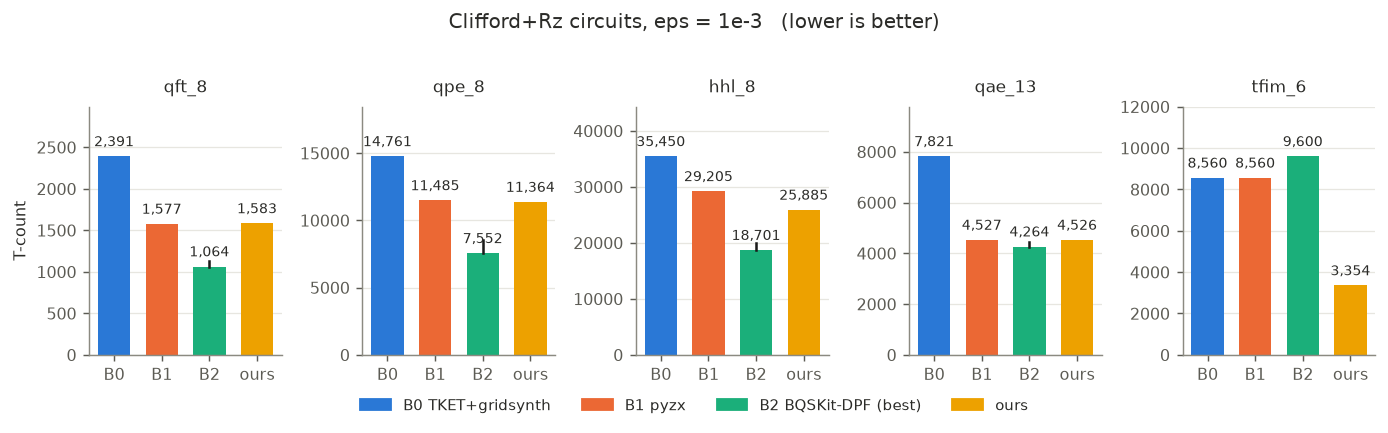

In [5]:
plt.rcParams.update({"figure.dpi": 130, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8b8a81", "axes.labelcolor": "#2b2b28",
                     "text.color": "#2b2b28", "xtick.color": "#5c5b54",
                     "ytick.color": "#5c5b54"})
NAMES = list(SERIES)


def panel(ax, circuit):
    row = bars.loc[circuit]
    vals = [row[n] for n in NAMES]
    xs = range(len(NAMES))
    ax.bar(xs, [0 if pd.isna(v) else v for v in vals],
           color=[COLORS[n] for n in NAMES], width=0.68, zorder=2)

    # B2 is stochastic: the thin line is its measured seed range, not an estimate.
    if not pd.isna(row["dpf_t_min"]) and row["dpf_t_max"] > row["dpf_t_min"]:
        i = NAMES.index("B2 BQSKit-DPF (best)")
        ax.plot([i, i], [row["dpf_t_min"], row["dpf_t_max"]], color="#1a1a19", lw=1.4, zorder=3)

    top = max([v for v in vals if not pd.isna(v)])
    for i, v in zip(xs, vals):
        if pd.isna(v):
            ax.text(i, top * 0.04, "no arm", ha="center", va="bottom", fontsize=7, color="#8b8a81",
                    rotation=90)
        else:
            ax.text(i, v + top * 0.035, f"{int(v):,}", ha="center", va="bottom", fontsize=7.5)

    flat = " (= input)" if row["ours_is_input"] else ""
    ax.set_title(f"{circuit}{flat}", fontsize=9.5, pad=8)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(["B0", "B1", "B2", "ours"])
    ax.set_ylim(0, top * 1.25)
    ax.grid(axis="y", color="#e7e6e0", lw=0.7, zorder=0)
    ax.set_axisbelow(True)


def figure(circuits, title, fname):
    fig, axes = plt.subplots(1, len(circuits), figsize=(2.15 * len(circuits), 2.9))
    for ax, c in zip(axes, circuits):
        panel(ax, c)
    axes[0].set_ylabel("T-count")
    handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[n]) for n in NAMES]
    fig.legend(handles, NAMES, loc="lower center", ncol=4, frameon=False,
               bbox_to_anchor=(0.5, -0.07), fontsize=8.5)
    fig.suptitle(title, fontsize=11, y=1.03)
    fig.tight_layout()
    fig.savefig(OUT / fname, bbox_inches="tight", facecolor="white")
    return fig


figure(ANGLE, "Clifford+Rz circuits, eps = 1e-3   (lower is better)", "t_counts_angle.png")
plt.show()

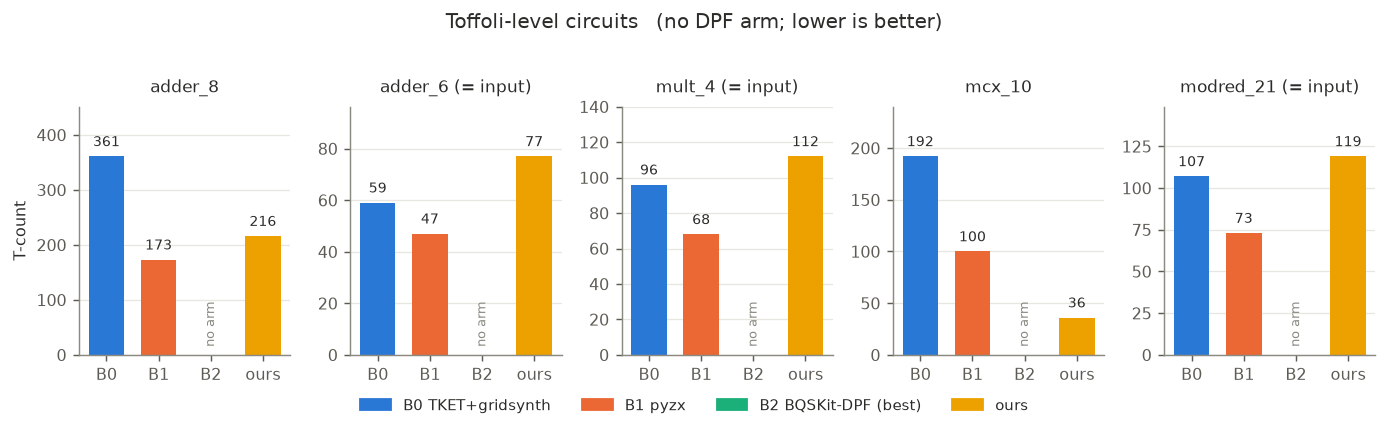

In [6]:
figure(TOFFOLI, "Toffoli-level circuits   (no DPF arm; lower is better)", "t_counts_toffoli.png")
plt.show()

## The gaps, stated plainly

`gap_to_best` is ours minus the best baseline on that circuit. Positive = we lose.

In [7]:
gaps = bars[["best_baseline", "best_baseline_t", "ours", "gap_to_best", "pct_vs_best",
             "ours_is_input"]].copy()
gaps["verdict"] = [("we win" if g < 0 else "tie" if g == 0 else "we lose")
                   for g in gaps["gap_to_best"]]
gaps.to_csv(OUT / "gaps.csv")
gaps

,best_baseline,best_baseline_t,ours,gap_to_best,pct_vs_best,ours_is_input,verdict
circuit,,,,,,,
qft_8,DPF Synth,1064,1583,519,48.8,False,we lose
qpe_8,DPF Synth,7552,11364,3812,50.5,False,we lose
hhl_8,DPF Synth,18701,25885,7184,38.4,False,we lose
qae_13,DPF Synth,4264,4526,262,6.1,False,we lose
tfim_6,TKET,8560,3354,-5206,-60.8,False,we win
adder_8,pyzx,173,216,43,NaN,False,we lose
adder_6,pyzx,47,77,30,NaN,True,we lose
mult_4,pyzx,68,112,44,NaN,True,we lose
mcx_10,pyzx,100,36,-64,NaN,False,we win
